# Challenge Sprint 4 — Classificação linear (Renewable Energy Production 2010–2020)
**Integrantes:**
* Gustavo Guedes Pereira — RM 569779
* Lucas Angelo — RM 569530
* Gustavo de Souza — RM 570746
* Arthur Tae — RM 570647
* Gabriel Rodrigues — RM 569322
* Murillo Boyadjian - RM 570774


## 1) Análise do dataset

### 1a) Carregar o dataset

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score)
import os
os.makedirs('resultados', exist_ok=True)

ARQUIVO = 'renewable_energy.csv'   # <- ajuste se o nome for outro
df = pd.read_csv(ARQUIVO)
print(df.shape)
df.head()

(1000, 11)


,Region,Energy_Source,Temperature_C,Wind_Speed_m_s,Solar_Radiation_kWh_m2,Rainfall_mm,Season,Efficiency_Ratio,Lagged_Production_MWh,Combined_Weather_Index,Energy_Class
0,North,Hydro,13.820937,14.362462,8.834648,3.350827,Winter,125.449109,1419.514155,1.565158,Medium
1,North,Solar,36.972782,19.110474,4.483191,48.767157,Winter,16.325089,4769.329958,0.621331,Low
2,East,Hydro,33.972875,0.364652,5.104325,40.848695,Winter,155.637061,1005.077719,0.156378,High
3,South,Solar,-2.965160,3.915560,6.265925,42.627371,Spring,675.516566,6294.250931,-5.180996,High
4,North,Wind,-3.813486,0.151257,9.263826,46.898262,Spring,626.048277,5550.263638,-3.346412,Medium


In [2]:
df.info()
print(df['Energy_Class'].value_counts())
print('Nulos por coluna:'); print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Region                  1000 non-null   object 
 1   Energy_Source           1000 non-null   object 
 2   Temperature_C           1000 non-null   float64
 3   Wind_Speed_m_s          1000 non-null   float64
 4   Solar_Radiation_kWh_m2  1000 non-null   float64
 5   Rainfall_mm             1000 non-null   float64
 6   Season                  1000 non-null   object 
 7   Efficiency_Ratio        1000 non-null   float64
 8   Lagged_Production_MWh   1000 non-null   float64
 9   Combined_Weather_Index  1000 non-null   float64
 10  Energy_Class            1000 non-null   object 
dtypes: float64(7), object(4)
memory usage: 86.1+ KB
Energy_Class
High      486
Medium    336
Low       178
Name: count, dtype: int64
Nulos por coluna:
Region                    0
Energy_Source            

### 1b) Encoding da variável-alvo

In [3]:
le = LabelEncoder()
df['Energy_Class_enc'] = le.fit_transform(df['Energy_Class'])
mapa = dict(zip(le.classes_, le.transform(le.classes_)))
print('Mapeamento das classes:', mapa)

Mapeamento das classes: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}


### 1c) Matriz de correlação (features numéricas + Energy_Class codificada)

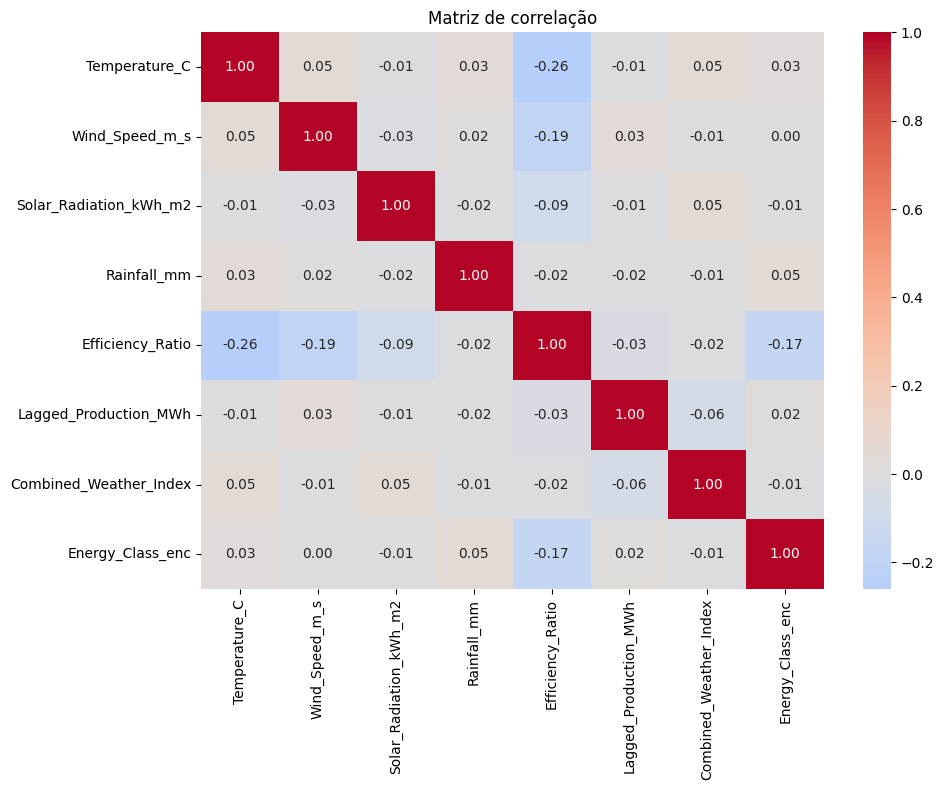

Correlação de cada feature com Energy_Class_enc:
Efficiency_Ratio         -0.166829
Rainfall_mm               0.045790
Temperature_C             0.028338
Lagged_Production_MWh     0.017410
Combined_Weather_Index   -0.014397
Solar_Radiation_kWh_m2   -0.012063
Wind_Speed_m_s            0.002793
Name: Energy_Class_enc, dtype: float64


In [4]:
# Mantém só colunas numéricas (colunas de texto/data ficam de fora da correlação)
num = df.select_dtypes(include='number').copy()
num = num.dropna()
corr = num.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlação')
plt.tight_layout()
plt.savefig('resultados/matriz_correlacao.png', dpi=150)
plt.show()

print('Correlação de cada feature com Energy_Class_enc:')
print(corr['Energy_Class_enc'].drop('Energy_Class_enc').sort_values(key=abs, ascending=False))

### 1d) Seleção de features (ou usar todas?)

In [5]:
# Pares de features muito correlacionadas entre si (|r| > 0.9 = redundância)
feats = [c for c in num.columns if c != 'Energy_Class_enc']
pares = [(a,b,corr.loc[a,b]) for i,a in enumerate(feats) for b in feats[i+1:] if abs(corr.loc[a,b])>0.9]
print('Pares redundantes:', pares if pares else 'nenhum')
print('Correlação fraca com o alvo (|r| < 0.1):',
      [c for c in feats if abs(corr.loc[c,'Energy_Class_enc'])<0.1])

Pares redundantes: nenhum
Correlação fraca com o alvo (|r| < 0.1): ['Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2', 'Rainfall_mm', 'Lagged_Production_MWh', 'Combined_Weather_Index']


A matriz de correlação mostra que nenhuma feature tem correlação forte com Energy_Class. A maior é Efficiency_Ratio (−0,17); as demais ficam abaixo de 0,05 em valor absoluto. Como não há pares de features com correlação acima de 0,9, não existe redundância a eliminar. Além disso, a correlação mede apenas relação linear entre pares e, aqui, a classe codificada tem uma ordem arbitrária (High=0, Low=1, Medium=2), o que torna essa medida pouco confiável para decidir quais variáveis descartar. Com apenas 7 features, remover alguma traria pouco ganho e poderia perder informação que só aparece em conjunto. Por isso, optou-se por usar todas as features.

In [6]:
# Defina as features usadas no modelo.
# Padrão: todas as numéricas. Se decidiu remover alguma, coloque o nome em REMOVER.
REMOVER = []   # ex.: ['Coluna_Redundante']
FEATURES = [c for c in feats if c not in REMOVER]
print('Features usadas:', FEATURES)

dados = df[FEATURES + ['Energy_Class_enc']].dropna()
X = dados[FEATURES]
y = dados['Energy_Class_enc']

Features usadas: ['Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2', 'Rainfall_mm', 'Efficiency_Ratio', 'Lagged_Production_MWh', 'Combined_Weather_Index']


## 2) Modelo

### 2a/2b) Escolha: **Regressão Logística** (`sklearn.linear_model.LogisticRegression`)

É linear porque calcula uma combinação linear das features, z = w1·x1 + w2·x2 + ... + b, e a classe depende de z. A fronteira de decisão é o conjunto de pontos onde z = 0 (ou onde duas classes empatam, no caso multiclasse): uma **reta** em 2 features, um **plano** em 3, um **hiperplano** em mais. A função sigmoide/softmax só transforma z em probabilidade; ela não curva a fronteira.

### 2c/2d) Treino nos dois cenários
Mesmas condições nos dois: mesmo modelo, mesma padronização, `random_state=42`, divisão estratificada (mantém a proporção das classes).

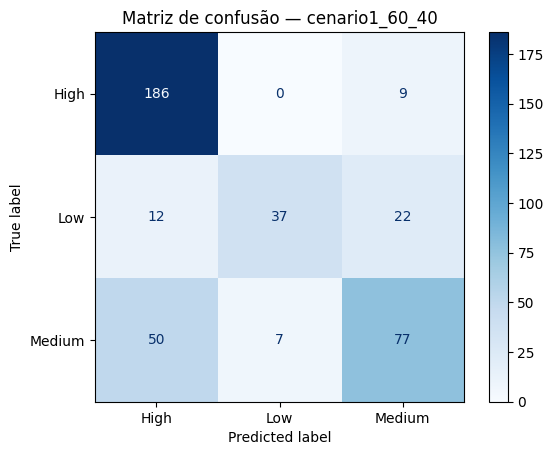

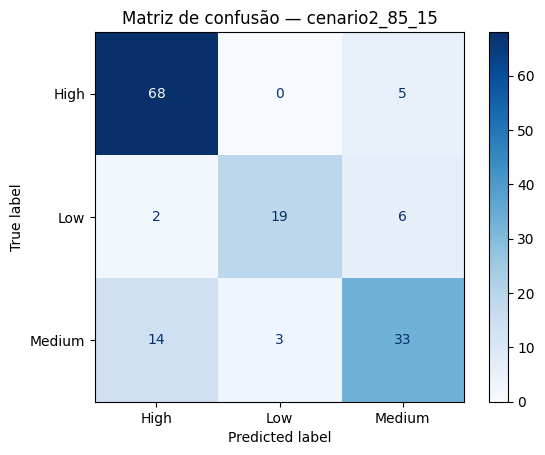

In [7]:
def rodar(test_size, nome):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y)
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
    modelo.fit(X_tr, y_tr)
    pred = modelo.predict(X_te)

    cm = confusion_matrix(y_te, pred)
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap='Blues')
    plt.title(f'Matriz de confusão — {nome}')
    plt.savefig(f'resultados/matriz_confusao_{nome}.png', dpi=150, bbox_inches='tight')
    plt.show()

    media = 'binary' if len(le.classes_)==2 else 'weighted'
    return {'Cenário': nome,
            'Treino': len(X_tr), 'Teste': len(X_te),
            'Acurácia': accuracy_score(y_te, pred),
            f'Precisão ({media})': precision_score(y_te, pred, average=media, zero_division=0),
            f'Recall ({media})': recall_score(y_te, pred, average=media, zero_division=0)}, cm

r1, cm1 = rodar(0.40, 'cenario1_60_40')
r2, cm2 = rodar(0.15, 'cenario2_85_15')

## 3) Avaliação da performance

In [8]:
res = pd.DataFrame([r1, r2]).round(4)
res.to_csv('resultados/metricas_cenarios.csv', index=False)
print('Matriz de confusão — cenário 1 (60/40):'); print(cm1)
print('Matriz de confusão — cenário 2 (85/15):'); print(cm2)
res

Matriz de confusão — cenário 1 (60/40):
[[186   0   9]
 [ 12  37  22]
 [ 50   7  77]]
Matriz de confusão — cenário 2 (85/15):
[[68  0  5]
 [ 2 19  6]
 [14  3 33]]


,Cenário,Treino,Teste,Acurácia,Precisão (weighted),Recall (weighted)
0,cenario1_60_40,600,400,0.75,0.7537,0.75
1,cenario2_85_15,850,150,0.80,0.7994,0.80


### 3c) Os resultados são adequados?
A acurácia foi de 75% (cenário 1) e 80% (cenário 2). Como a classe mais comum (High) representa cerca de 49% dos dados, um modelo que sempre chutasse “High” acertaria cerca de metade; portanto, o modelo aprendeu algo útil. O desempenho é razoável, mas não excelente. A classe High é muito bem identificada (recall de 95% e 93%). A classe Medium é a mais difícil (recall de 57% e 66%), sendo frequentemente confundida com High. A classe Low tem boa precisão (84% e 86%), mas recall mais baixo (52% e 70%): quando o modelo diz “Low”, costuma estar certo, mas deixa passar vários casos de Low. Isso é esperado, pois um modelo linear tem fronteiras simples e as features têm correlação fraca com a classe.

### 3d) Comparação 40% vs 15% de teste
No cenário 2 (15% de teste) todas as métricas foram um pouco melhores: acurácia de 80% contra 75%, precisão de 0,80 contra 0,75 e recall de 0,80 contra 0,75. O padrão dos erros foi o mesmo nos dois: High acertada quase sempre e Medium confundida com High. Isso indica que o resultado é consistente. A melhora provavelmente vem de o cenário 2 treinar com mais dados (85% contra 60%), mas também pode ser efeito da amostra, já que o teste menor (150 linhas) é mais sensível à sorte da divisão.

### 3e) Teste maior vs menor
- **Teste maior (40%):** estimativa de desempenho mais confiável (mais exemplos avaliados, menos sorte); mas sobram menos dados para treinar (60%), o que pode piorar o modelo.
- **Teste menor (15%):** mais dados para treinar (85%), tendendo a um modelo melhor; mas a avaliação é mais instável — poucas linhas no teste, e classes raras podem quase não aparecer, deixando precisão e recall pouco confiáveis.
- Em ambos os casos, a métrica depende da divisão sorteada; validação cruzada reduziria essa dependência.

In [9]:
print('Proporção das classes (referência para a acurácia):')
print(y.map(dict(enumerate(le.classes_))).value_counts(normalize=True).round(4))

Proporção das classes (referência para a acurácia):
Energy_Class_enc
High      0.486
Medium    0.336
Low       0.178
Name: proportion, dtype: float64
